# 02.3 · Gradient boosting: will a new Kindle book become popular?

**Project:** Digital Publishing Opportunity Intelligence

**Author:** Stefan Radević · Data Science Bootcamp · Capstone project

## 1. TL;DR

**Key findings**

- Gradient boosting has the best validation result (**ROC AUC 0.802**) and reaches **0.809** on the test books, with accuracy **75.7%**, precision **66.2%** and recall **51.1%**.
- The **author's earlier books** come first, then **pages**.
- With **only the draft** (niche, pages, title words, series) the ROC AUC falls to **0.720**. The draft helps, but the author's history helps more.
- Popular **first books** remain hard to find (recall **0.038**).

## 2. Recap

**Question.** Can we predict, from the characteristics of a book draft, whether a new Kindle book will reach at least 100 ratings in
its first 12 months on Amazon?

**From the EDA (`01_eda.ipynb`).** The table has 135,839 books published from 2019 to 2021. A book is **popular** (`popular_first_year` = 1)
if it has at least 100 estimated ratings in its first 12 months. This is 32.4% of the books. Section 9.18 of the EDA shows how the
number was chosen.

**This notebook** trains one model and compares it with a simple baseline, following the course steps: split the data, tune on
the training books only, and look at the test books once at the end.

## 3. Setup

I load the libraries and the table from the EDA. `RANDOM_STATE` makes the split and the model the same every time.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder

PROJECT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
PROCESSED = PROJECT / "data" / "processed"
RANDOM_STATE = 42
TARGET = "popular_first_year"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

books = pd.read_parquet(PROCESSED / "kindle_books_popularity.parquet")
print("Table:", books.shape)
print(f"Popular books: {books[TARGET].sum():,} ({books[TARGET].mean():.1%})")
books.head(3)

Table: (135839, 15)
Popular books: 44,036 (32.4%)


,parent_asin,title,author,niche,pages,title_words,is_series,self_published,author_earlier_books,publication_year,price,rating_number,first_year_reviews,first_year_ratings,popular_first_year
0,B07NDWT66X,51 Inspirational Sweet Western Romances Box Se...,Katie Wyatt,Religion & Spirituality,2845.0,18,1,0,215,2019,0.00,405,7.0,405.0,1
1,B08NRPBGGR,Back To You,Bates,Literature & Fiction,254.0,3,0,0,0,2021,6.99,38,3.0,28.5,0
2,B09L6VDZTF,The Senders of Fate: Warrior of the Dark Book 2,Garnet Hart,Literature & Fiction,312.0,10,1,1,4,2021,0.00,3,1.0,3.0,0


- The table has **135,839 books** and 15 columns.
- **44,036 books (32.4%)** are popular, so about one book in three is in the positive class.

## 4. Feature preparation

The model receives the characteristics of a draft and how it is published. Price, publication year, ratings, reviews and stars are
not used (`01_eda.ipynb`, section 11). Tree models do not need scaling or a logarithm, so I keep the original columns.

In [2]:
def prepare_features(data):
    return data.copy()


NUMERIC = ["pages", "title_words", "author_earlier_books", "is_series", "self_published"]
CATEGORICAL = ["niche"]
FEATURES = NUMERIC + CATEGORICAL
print("Features:", FEATURES)
books[FEATURES].isna().sum().to_frame("empty values").T

Features: ['pages', 'title_words', 'author_earlier_books', 'is_series', 'self_published', 'niche']


,pages,title_words,author_earlier_books,is_series,self_published,niche
empty values,6098,0,0,0,0,0


- The model gets **6 features**. Only `pages` has empty values (6,098 books), and this model can work with them directly.

## 5. Train/test split

I keep **20% of the books for the final test**. All books of one author stay on the same side, so the test shows how the model works for
**authors it has not seen**. `StratifiedGroupKFold` does this and also keeps a similar share of popular books on both sides. It goes
one step beyond the plain `train_test_split` from the course, because a random split would put books by the same author on both sides.

In [3]:
groups = books["author"].fillna(books["parent_asin"])
X, y = books[FEATURES], books[TARGET]
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_index, test_index = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y.iloc[train_index], y.iloc[test_index]
groups_train, groups_test = groups.iloc[train_index], groups.iloc[test_index]
test_books = books.iloc[test_index].copy()

print(f"Training books: {len(X_train):,} ({y_train.mean():.1%} popular) | authors: {groups_train.nunique():,}")
print(f"Test books:     {len(X_test):,} ({y_test.mean():.1%} popular) | authors: {groups_test.nunique():,}")
print("Authors on both sides:", len(set(groups_train) & set(groups_test)))

Training books: 108,670 (32.4% popular) | authors: 64,046
Test books:     27,169 (32.4% popular) | authors: 16,017
Authors on both sides: 0


- **108,670 training books** and **27,169 test books**, each with **32.4%** popular books.
- **No author is on both sides** (0 shared authors), so the test really shows new authors.

## 6. Baseline

The baseline ignores the book and always predicts the most common answer. A model is useful only if it does better. The function
`measures` calculates the same numbers for every model.

In [4]:
def measures(name, true, probability, threshold=0.5):
    predicted = (probability >= threshold).astype(int)
    return {"model": name, "accuracy": accuracy_score(true, predicted),
            "precision": precision_score(true, predicted, zero_division=0), "recall": recall_score(true, predicted, zero_division=0),
            "f1": f1_score(true, predicted, zero_division=0), "roc_auc": roc_auc_score(true, probability)}


baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_probability = baseline.predict_proba(X_test)[:, 1]
pd.DataFrame([measures("baseline (test)", y_test, baseline_probability)]).set_index("model").round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
baseline (test),0.676,0.0,0.0,0.0,0.5


- The baseline always predicts "not popular". It is right for **67.6%** of the test books, but finds no popular book: precision, recall and F1 are **0**.
- Its ROC AUC is **0.5**, the same as guessing. A useful model must beat these numbers.

## 7. Candidate model

**Gradient boosting** also uses trees, but builds them one after another, and each new tree corrects the errors of the previous ones.

- I use `HistGradientBoostingClassifier`, the fast version in scikit-learn. It goes beyond the basic version from the course because this
  table is large, and it handles empty `pages` by itself.
- `learning_rate` sets how much each tree changes the result, `max_leaf_nodes` how complex a tree can be, and `max_iter` is the number of
  trees. `GridSearchCV` tries them with 5 folds and keeps authors together.

In [5]:
preprocess = ColumnTransformer([
    ("numeric", "passthrough", NUMERIC),
    ("niche", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
])
pipeline = Pipeline([("prepare", preprocess),
                     ("model", HistGradientBoostingClassifier(min_samples_leaf=50, early_stopping=False, random_state=RANDOM_STATE))])
grid = {"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [15, 31], "model__max_iter": [150, 300]}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(pipeline, grid, scoring="roc_auc", cv=cv, return_train_score=True)
search.fit(X_train, y_train, groups=groups_train)
best_model = search.best_estimator_

columns = [c for c in pd.DataFrame(search.cv_results_).columns if c.startswith("param_")]
results = pd.DataFrame(search.cv_results_)[columns + ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]]
results.columns = [c.replace("param_model__", "") for c in results.columns]
print("Best settings:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})
print(f"Best validation ROC AUC: {search.best_score_:.4f}")
results.sort_values("rank_test_score").round(4)

Best settings: {'learning_rate': 0.05, 'max_iter': 150, 'max_leaf_nodes': 31}
Best validation ROC AUC: 0.8018


,learning_rate,max_iter,max_leaf_nodes,mean_train_score,mean_test_score,std_test_score,rank_test_score
1,0.05,150,31,0.8160,0.8018,0.0032,1
3,0.05,300,31,0.8230,0.8010,0.0035,2
2,0.05,300,15,0.8138,0.8008,0.0035,3
4,0.10,150,15,0.8139,0.8006,0.0036,4
0,0.05,150,15,0.8092,0.8006,0.0032,5
6,0.10,300,15,0.8209,0.8005,0.0039,6
5,0.10,150,31,0.8230,0.8004,0.0037,7
7,0.10,300,31,0.8339,0.7990,0.0038,8


- The best settings are **learning rate 0.05, 31 leaves and 150 trees**, with a validation ROC AUC of **0.8018**.
- More trees and a higher learning rate raise the training score but not the validation score: the combination 0.1, 31 leaves and 300 trees reaches 0.8339 in training and only 0.7990 in validation.
- The chosen model has a small gap (0.8160 against 0.8018).

## 8. Evaluation

Now I use the **test books once**. I compare training and test results with the baseline. If the model were much better on training
books, it would be overfitting. I use a threshold of 0.5: a probability of 0.5 or more means "popular".

In [6]:
train_probability = best_model.predict_proba(X_train)[:, 1]
test_probability = best_model.predict_proba(X_test)[:, 1]
test_predicted = (test_probability >= 0.5).astype(int)
scores = pd.DataFrame([measures("baseline (test)", y_test, baseline_probability),
                       measures("Gradient boosting (train)", y_train, train_probability),
                       measures("Gradient boosting (test)", y_test, test_probability)]).set_index("model")
scores.round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
baseline (test),0.676,0.000,0.000,0.000,0.500
Gradient boosting (train),0.762,0.669,0.525,0.588,0.814
Gradient boosting (test),0.757,0.662,0.511,0.577,0.809


- On the test books: accuracy **0.757**, precision **0.662**, recall **0.511**, F1 **0.577** and ROC AUC **0.809**. All are far above the baseline.
- Training ROC AUC (0.814) is close to test (0.809), so overfitting is small.

The **confusion matrix** counts correct answers and the two kinds of errors. The **ROC curve** shows how well the model ranks books at every
threshold; the dashed line is guessing.

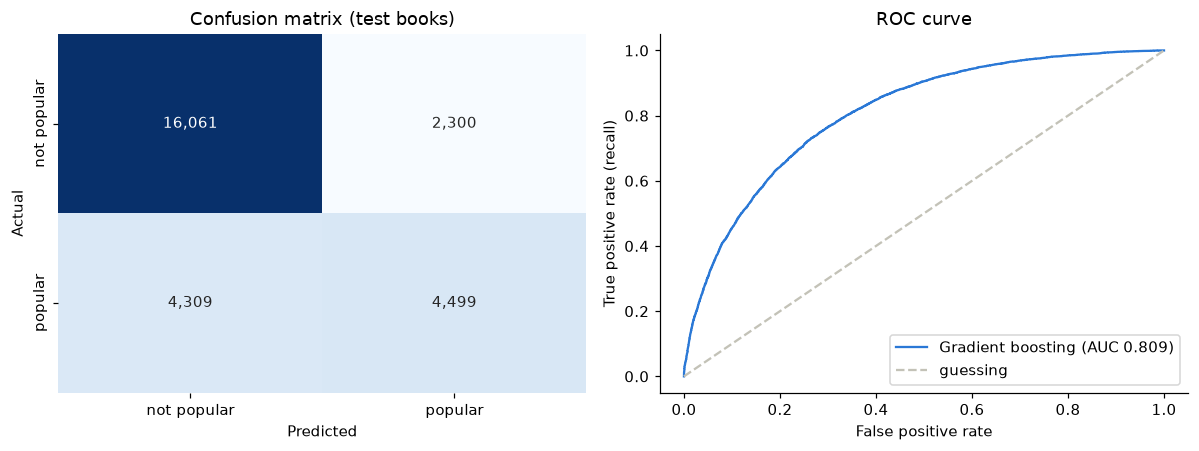

In [7]:
matrix = confusion_matrix(y_test, test_predicted)
fpr, tpr, _ = roc_curve(y_test, test_probability)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["not popular", "popular"], yticklabels=["not popular", "popular"])
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_title("Confusion matrix (test books)")
axes[1].plot(fpr, tpr, color=BLUE, label=f"Gradient boosting (AUC {roc_auc_score(y_test, test_probability):.3f})")
axes[1].plot([0, 1], [0, 1], color=GREY, linestyle="--", label="guessing")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curve")
axes[1].legend()
plt.tight_layout()
plt.show()

- The model finds **4,499** of the 8,808 popular books and misses **4,309**.
- It correctly rejects **16,061** books and raises **2,300** false alarms.

The **threshold** can be changed. A lower one finds more popular books but raises more false alarms. The second table checks whether the
probabilities can be read as chances: within each probability range I compare the average prediction with the real share of popular
books.

In [8]:
rows = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    row = measures(threshold, y_test, test_probability, threshold)
    row["books called popular"] = int((test_probability >= threshold).sum())
    rows.append(row)
threshold_table = pd.DataFrame(rows).rename(columns={"model": "threshold"}).set_index("threshold").drop(columns="roc_auc")

ranges = pd.cut(test_probability, np.linspace(0, 1, 11), include_lowest=True)
reliability = pd.DataFrame({"probability": test_probability, "actual": y_test.to_numpy()}).groupby(ranges, observed=True).agg(
    books=("actual", "size"), predicted_pct=("probability", lambda s: s.mean() * 100), actual_pct=("actual", lambda s: s.mean() * 100))
display(threshold_table.round(3))
reliability.round(1)

,accuracy,precision,recall,f1,books called popular
threshold,,,,,
0.3,0.711,0.537,0.790,0.639,12951
0.4,0.746,0.599,0.659,0.627,9697
0.5,0.757,0.662,0.511,0.577,6799
0.6,0.748,0.728,0.357,0.479,4320
0.7,0.723,0.790,0.197,0.316,2200


,books,predicted_pct,actual_pct
"(-0.001, 0.1]",6185,5.6,4.9
"(0.1, 0.2]",4411,14.5,14.6
"(0.2, 0.3]",3622,24.9,25.0
"(0.3, 0.4]",3254,35.0,35.3
"(0.4, 0.5]",2898,44.8,45.1
"(0.5, 0.6]",2479,54.9,54.6
"(0.6, 0.7]",2120,65.0,66.4
"(0.7, 0.8]",1841,74.9,77.0
"(0.8, 0.9]",359,81.9,89.1


- At **0.3** it finds **79.0%** of the popular books with a precision of 53.7%. At **0.7** it is right **79.0%** of the time but finds 19.7%.
- F1 is highest at 0.3 (0.639). I keep 0.5 for the comparison.
- The probabilities are very close to the real shares: up to 0.8 the largest difference is about 2 points. In the range 0.8 to 0.9 the model is too careful (81.9% against 89.1%).

## 9. Error analysis

Where does the model do well or badly? I compare groups of test books. `actual_%` is the real share of popular books and `predicted_%` is the
share the model calls popular.

In [9]:
test_books["probability"] = test_probability
test_books["predicted"] = test_predicted
test_books["route"] = np.where(test_books["self_published"] == 1, "self-published", "publisher")
test_books["experience"] = pd.cut(test_books["author_earlier_books"], [-1, 0, 2, 9, np.inf],
                                  labels=["first book", "1-2 earlier", "3-9 earlier", "10+ earlier"])


def group_report(column, minimum=300):
    rows = []
    for group, part in test_books.groupby(column, observed=True):
        if len(part) >= minimum and part[TARGET].nunique() == 2:
            rows.append({column: group, "books": len(part), "actual_%": part[TARGET].mean() * 100, "predicted_%": part["predicted"].mean() * 100,
                         "precision": precision_score(part[TARGET], part["predicted"], zero_division=0),
                         "recall": recall_score(part[TARGET], part["predicted"], zero_division=0),
                         "roc_auc": roc_auc_score(part[TARGET], part["probability"])})
    return pd.DataFrame(rows).set_index(column)


display(group_report("route").round(3))
display(group_report("experience").round(3))
niche_report = group_report("niche").sort_values("recall", ascending=False)
pd.concat([niche_report.head(4), niche_report.tail(4)]).round(3)

,books,actual_%,predicted_%,precision,recall,roc_auc
route,,,,,,
publisher,9991,46.912,38.375,0.690,0.565,0.743
self-published,17178,23.990,17.260,0.625,0.450,0.816


,books,actual_%,predicted_%,precision,recall,roc_auc
experience,,,,,,
first book,8411,13.042,0.820,0.609,0.038,0.771
1-2 earlier,4712,20.947,3.247,0.608,0.094,0.744
3-9 earlier,5729,32.798,14.540,0.563,0.250,0.699
10+ earlier,8317,58.254,69.063,0.678,0.804,0.709


,books,actual_%,predicted_%,precision,recall,roc_auc
niche,,,,,,
Romance,3112,47.943,43.862,0.666,0.609,0.726
Literature & Fiction,10025,35.641,32.309,0.664,0.602,0.809
"Cookbooks, Food & Wine",340,24.118,24.706,0.571,0.585,0.808
"Mystery, Thriller & Suspense",1701,40.682,33.510,0.672,0.553,0.779
Biographies & Memoirs,606,23.432,6.106,0.595,0.155,0.820
"Health, Fitness & Dieting",362,22.099,3.591,0.692,0.112,0.838
Children's eBooks,1853,15.704,2.375,0.682,0.103,0.812
Business & Money,988,12.449,0.709,0.429,0.024,0.758


- **Route:** recall is **0.450** for self-published books and 0.565 for publisher books. Ranking is better for self-published books (ROC AUC 0.816 against 0.743).
- **Experience:** recall is **0.038** for first books, 0.094 with 1–2 earlier books, 0.250 with 3–9 and **0.804** with 10 or more. For first books the ROC AUC is 0.771, so the model can rank them, but their probabilities rarely pass 0.5.
- **Niches:** recall is highest in **Romance** (0.609) and **Literature & Fiction** (0.602), and very low in **Business & Money** (0.024).

I also look at the books where the model was most confident and wrong.

In [10]:
show = ["title", "niche", "pages", "is_series", "self_published", "author_earlier_books", "first_year_ratings", "probability"]
false_alarms = test_books[(test_books["predicted"] == 1) & (test_books[TARGET] == 0)].nlargest(5, "probability")[show]
missed = test_books[(test_books["predicted"] == 0) & (test_books[TARGET] == 1)].nsmallest(5, "probability")[show]
display(false_alarms.round(2))
display(missed.round(2))
print("Missed popular books:", f"{((test_books['predicted'] == 0) & (test_books[TARGET] == 1)).sum():,}",
      "| self-published:", f"{test_books.loc[(test_books['predicted'] == 0) & (test_books[TARGET] == 1), 'self_published'].mean():.1%}",
      "| median earlier books:", test_books.loc[(test_books['predicted'] == 0) & (test_books[TARGET] == 1), 'author_earlier_books'].median())

,title,niche,pages,is_series,self_published,author_earlier_books,first_year_ratings,probability
102713,Between Bloode and Craft: Paranormal Vampire R...,"Mystery, Thriller & Suspense",304.0,1,0,105,87.00,0.85
71225,Kylian: An Urban Fantasy (Circle of Assassins ...,"Mystery, Thriller & Suspense",211.0,1,0,77,18.67,0.84
34145,An Unwilling Conquest (Lester Family Book 2),Romance,319.0,1,0,110,0.00,0.84
5021,Fair Juno: A Regency Romance (Historical Book 13),Romance,304.0,1,0,102,0.00,0.84
16954,A Steele for Christmas (Forged of Steele Book 9),Literature & Fiction,220.0,1,0,158,0.00,0.82


,title,niche,pages,is_series,self_published,author_earlier_books,first_year_ratings,probability
124378,Approaching (Almost) Any Machine Learning Problem,Education & Teaching,NaN,0,1,0,711.00,0.02
295,Humanity Lost,Science Fiction & Fantasy,53.0,0,1,0,195.49,0.02
67153,Grumpy Trumpy: A Bad Hombre Parody,Humor & Entertainment,24.0,0,1,0,453.33,0.02
77414,Pentest Secrets: Breaking The Unbreakable Ente...,Computers & Technology,NaN,0,1,0,115.00,0.02
39296,Personal Finance for Beginners - A Simple Guid...,Business & Money,43.0,0,1,1,305.33,0.02


Missed popular books: 4,309 | self-published: 52.6% | median earlier books: 3.0


- **False alarms:** the most confident ones are publisher books in a series, from authors with 77 to 158 earlier books, with only 0 to 87 first-year ratings.
- **Missed books:** the most confident ones are self-published books by authors with 0 or 1 earlier books, with 115 to 711 first-year ratings. Where the length is known they are short (24 to 53 pages).
- Of the **4,309** missed popular books, **52.6%** are self-published, and their median author has 3 earlier books.

## 10. Interpretation

**Permutation importance** shuffles one feature in the test books and measures how much the ROC AUC falls. A large fall means the model relies
on that feature. I use 8,000 test books to keep this quick.

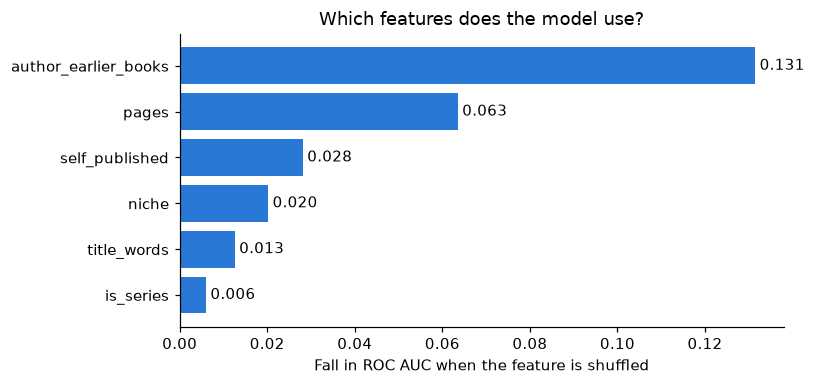

In [11]:
sample = X_test.sample(8000, random_state=RANDOM_STATE)
importance = permutation_importance(best_model, sample, y_test.loc[sample.index], scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE)
importance_table = pd.Series(importance.importances_mean, index=FEATURES, name="fall in ROC AUC").sort_values()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bars = ax.barh(importance_table.index, importance_table.values, color=BLUE)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_xlabel("Fall in ROC AUC when the feature is shuffled")
ax.set_title("Which features does the model use?")
plt.tight_layout()
plt.show()

- The **author's earlier books** are by far the most important (**0.131**).
- **Pages** come second (**0.063**), then **self-published** (0.028), **niche** (0.020), **title words** (0.013) and **series** (0.006).

A tree model has no simple weights, so I look at its behaviour. I take 3,000 training books, give all of them the same value of one feature,
and average the predicted chance. This is called **partial dependence**.

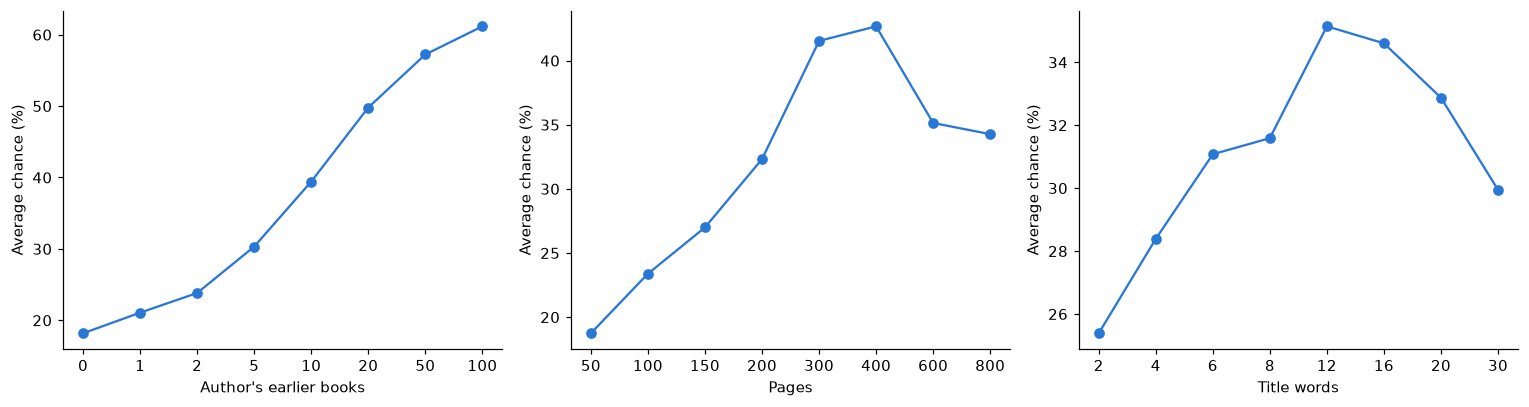

Author's earlier books {0: 18.2, 1: 21.1, 2: 23.8, 5: 30.3, 10: 39.4, 20: 49.8, 50: 57.2, 100: 61.2}
Pages {50: 18.7, 100: 23.4, 150: 27.0, 200: 32.3, 300: 41.5, 400: 42.7, 600: 35.1, 800: 34.3}
Title words {2: 25.4, 4: 28.4, 6: 31.1, 8: 31.6, 12: 35.1, 16: 34.6, 20: 32.9, 30: 29.9}
Series: no 30.1 | yes 34.1
Publisher 37.8 | self-published 28.9


In [12]:
reference = X_train.sample(3000, random_state=RANDOM_STATE)


def average_chance(column, values):
    return pd.Series([best_model.predict_proba(reference.assign(**{column: value}))[:, 1].mean() * 100 for value in values],
                     index=values, name="average chance %")


effects = [("author_earlier_books", [0, 1, 2, 5, 10, 20, 50, 100], "Author's earlier books"),
           ("pages", [50, 100, 150, 200, 300, 400, 600, 800], "Pages"), ("title_words", [2, 4, 6, 8, 12, 16, 20, 30], "Title words")]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
tables = {}
for ax, (column, values, label) in zip(axes, effects):
    tables[label] = average_chance(column, values)
    ax.plot(range(len(values)), tables[label].values, marker="o", color=BLUE)
    ax.set_xticks(range(len(values)), values)
    ax.set_xlabel(label)
    ax.set_ylabel("Average chance (%)")
plt.tight_layout()
plt.show()
for label, table in tables.items():
    print(label, table.round(1).to_dict())
print("Series: no", round(average_chance("is_series", [0]).iloc[0], 1), "| yes", round(average_chance("is_series", [1]).iloc[0], 1))
print("Publisher", round(average_chance("self_published", [0]).iloc[0], 1), "| self-published", round(average_chance("self_published", [1]).iloc[0], 1))

- **Earlier books:** the average chance rises from **18.2%** for a first book to **39.4%** with 10 earlier books and **61.2%** with 100.
- **Pages:** it rises from **18.7%** at 50 pages to **42.7%** at 400, then falls to 34.3% at 800.
- **Title words:** it is highest around 12 words (35.1%), with small differences.
- **Series** gives 34.1% against 30.1%, and a **publisher** 37.8% against 28.9% for self-published books.
- These are patterns in the model, not proof that a change would cause the same result.

The strongest feature describes the **author**, not the draft. So I check how much is left when the model sees **only the draft**: niche, pages, title
words and series. I train the same model with the same settings on the same training books.

In [13]:
DRAFT_ONLY = ["niche", "pages", "title_words", "is_series"]
draft_preprocess = ColumnTransformer([
    ("numeric", "passthrough", ["pages", "title_words", "is_series"]),
    ("niche", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
])
settings = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
draft_model = Pipeline([("prepare", draft_preprocess),
                        ("model", HistGradientBoostingClassifier(**settings, min_samples_leaf=50, early_stopping=False, random_state=RANDOM_STATE))])
draft_model.fit(X_train[DRAFT_ONLY], y_train)
draft_probability = draft_model.predict_proba(X_test[DRAFT_ONLY])[:, 1]
pd.DataFrame([measures("baseline", y_test, baseline_probability), measures("draft only (4 features)", y_test, draft_probability),
              measures("draft + publishing route + earlier books (6 features)", y_test, test_probability)]).set_index("model").round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
baseline,0.676,0.000,0.000,0.000,0.500
draft only (4 features),0.699,0.560,0.337,0.421,0.720
draft + publishing route + earlier books (6 features),0.757,0.662,0.511,0.577,0.809


- With **only the draft features** the ROC AUC is **0.720**, the accuracy **0.699**, the precision **0.560** and the recall **0.337**.
- This is clearly better than the baseline (0.500), so the draft itself carries useful information.
- Adding the publishing route and the author's earlier books raises the ROC AUC to **0.809**. Much of the predictive power comes from the author, not from the draft.

Finally I give the model a few **invented book drafts** to see the estimated chance of reaching 100 ratings in the first year. All have 250 pages and
an 8-word title unless the description says otherwise.

In [14]:
examples = pd.DataFrame([
    ["Romance, self-published first book", "Romance", 250, 8, 0, 1, 0],
    ["Same book in a series", "Romance", 250, 8, 1, 1, 0],
    ["In a series, author has 10 earlier books", "Romance", 250, 8, 1, 1, 10],
    ["First book with a publisher", "Romance", 250, 8, 0, 0, 0],
    ["First book, 400 pages", "Romance", 400, 8, 0, 1, 0],
    ["Education, self-published first book", "Education & Teaching", 250, 8, 0, 1, 0],
], columns=["draft", "niche", "pages", "title_words", "is_series", "self_published", "author_earlier_books"])
examples["chance of 100+ ratings %"] = best_model.predict_proba(prepare_features(examples)[FEATURES])[:, 1] * 100
examples.drop(columns=["title_words"]).round(1)

,draft,niche,pages,is_series,self_published,author_earlier_books,chance of 100+ ratings %
0,"Romance, self-published first book",Romance,250,0,1,0,16.9
1,Same book in a series,Romance,250,1,1,0,26.6
2,"In a series, author has 10 earlier books",Romance,250,1,1,10,52.6
3,First book with a publisher,Romance,250,0,0,0,29.2
4,"First book, 400 pages",Romance,400,0,1,0,18.9
5,"Education, self-published first book",Education & Teaching,250,0,1,0,6.2


- A self-published first Romance book has an estimated chance of **16.9%**; in a series **26.6%**; in a series by an author with 10 earlier books **52.6%**.
- With a publisher the first book has **29.2%**, and with 400 pages **18.9%**. In Education & Teaching it has **6.2%**.
- These are **associations, not promises**.

## 11. Limitations & ethics

**Limitations**

- **The target is estimated.** First-year ratings come from dated reviews scaled to Amazon's total ratings, so books close to 100 can fall on the wrong side.
- **Ratings are not sales.** The model predicts reader response, not copies sold or income.
- **Only books with at least one review in the file are included**, so real chances for a new book are probably lower.
- `self_published` comes from my rule, and `author_earlier_books` counts only books in this catalog. Some "authors" are really companies.
- Marketing, cover, writing quality and reviews are not in the data.
- The model was built on books from 2019–2021, so it may not hold for later years.
- The results show **associations, not causes**.

**Ethics**

- The model favours experienced authors. It should not decide which authors or books deserve support.
- It is meant as **information for an author**. A low chance does not mean that a book is bad.

## 12. Conclusion

I save the test predictions and the main results for the comparison notebook.

In [15]:
output = test_books[["parent_asin", TARGET, "niche", "self_published", "author_earlier_books", "probability", "predicted"]]
output.to_parquet(PROCESSED / "predictions_popularity_gradient_boosting.parquet", index=False)
summary = {"model": "Gradient boosting", "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
           "cv_roc_auc": float(search.best_score_), "cv_std": float(search.cv_results_["std_test_score"][search.best_index_]),
           "train_roc_auc": float(roc_auc_score(y_train, train_probability)),
           "importance": {k: float(v) for k, v in importance_table.sort_values(ascending=False).items()}}
(PROCESSED / "results_popularity_gradient_boosting.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
print("Saved predictions:", output.shape)

Saved predictions: (27169, 7)


**What worked.** Gradient boosting has the best validation result, little overfitting and reliable probabilities.

**What did not work.** It still finds few popular first books (recall 0.038), and it depends strongly on the author's earlier books.

**Next.** **02.4** compares the three models and chooses the final one.